In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
df = pd.read_csv(r"C:\MyFolder\train.csv")

print("Dataset shape:", df.shape)

print("\nFirst 5 records:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

Dataset shape: (9800, 18)

First 5 records:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680



Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   str    
 2   Order Date     9800 non-null   str    
 3   Ship Date      9800 non-null   str    
 4   Ship Mode      9800 non-null   str    
 5   Customer ID    9800 non-null   str    
 6   Customer Name  9800 non-null   str    
 7   Segment        9800 non-null   str    
 8   Country        9800 non-null   str    
 9   City           9800 non-null   str    
 10  State          9800 non-null   str    
 11  Postal Code    9789 non-null   float64
 12  Region         9800 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row ID,9800.0,NaN,NaN,NaN,4900.5,2829.160653,1.0,2450.75,4900.5,7350.25,9800.0
Order ID,9800,4922,CA-2018-100111,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,9800,1230,05/09/2017,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Date,9800,1326,26/09/2018,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Mode,9800,4,Standard Class,5859,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,9800,793,WB-21850,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,9800,793,William Brown,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,9800,3,Consumer,5101,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,9800,1,United States,9800,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,9800,529,New York City,891,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Missing value percentage
missing_pct = (df.isnull().mean() * 100).round(2)

display(missing_pct.to_frame("Missing Percentage"))

# Check invalid or non-positive sales
print("Sales less than or equal to zero:",
      (df["Sales"] <= 0).sum())

# Check invalid dates
print("Missing order dates:", df["Order Date"].isna().sum())
print("Missing ship dates:", df["Ship Date"].isna().sum())

# Check if shipping date is before order date
invalid_shipping = df["Ship Date"] < df["Order Date"]

print("Ship dates before order dates:", invalid_shipping.sum())

# Check unique values in important columns
for col in ["Category", "Sub-Category", "Region",
            "Segment", "Ship Mode"]:
    print(f"\n{col}: {df[col].nunique()} unique values")
    print(df[col].value_counts().head(10))

,Missing Percentage
Row ID,0.00
Order ID,0.00
Order Date,0.00
Ship Date,0.00
Ship Mode,0.00
Customer ID,0.00
Customer Name,0.00
Segment,0.00
Country,0.00
City,0.00


Sales less than or equal to zero: 0
Missing order dates: 0
Missing ship dates: 0
Ship dates before order dates: 1139

Category: 3 unique values
Category
Office Supplies    5909
Furniture          2078
Technology         1813
Name: count, dtype: int64

Sub-Category: 17 unique values
Sub-Category
Binders        1492
Paper          1338
Furnishings     931
Phones          876
Storage         832
Art             785
Accessories     756
Chairs          607
Appliances      459
Labels          357
Name: count, dtype: int64

Region: 4 unique values
Region
West       3140
East       2785
Central    2277
South      1598
Name: count, dtype: int64

Segment: 3 unique values
Segment
Consumer       5101
Corporate      2953
Home Office    1746
Name: count, dtype: int64

Ship Mode: 4 unique values
Ship Mode
Standard Class    5859
Second Class      1902
First Class       1501
Same Day           538
Name: count, dtype: int64


In [6]:
total_sales = df["Sales"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
total_products = df["Product ID"].nunique()
average_order_value = total_sales / total_orders

print("========== SALES PERFORMANCE ==========")
print(f"Total Sales: ${total_sales:,.2f}")
print(f"Unique Orders: {total_orders:,}")
print(f"Unique Customers: {total_customers:,}")
print(f"Unique Products: {total_products:,}")
print(f"Average Sales per Order: ${average_order_value:,.2f}")
print(f"Average Sales per Record: ${df['Sales'].mean():,.2f}")

========== SALES PERFORMANCE ==========
Total Sales: $2,261,536.78
Unique Orders: 4,922
Unique Customers: 793
Unique Products: 1,861
Average Sales per Order: $459.48
Average Sales per Record: $230.77


,Total Sales
Category,
Technology,827455.8730
Furniture,728658.5757
Office Supplies,705422.3340


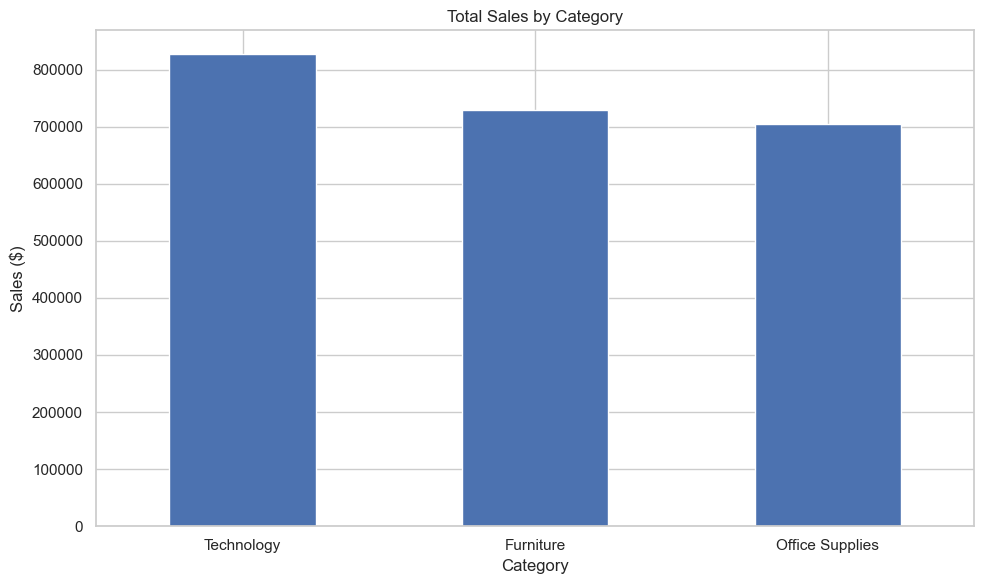

In [7]:
#Which product categories generate the most sales?
category_sales = (
    df.groupby("Category")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

display(category_sales.to_frame("Total Sales"))

category_sales.plot(kind="bar", rot=0)

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales ($)")
plt.tight_layout()
plt.show()

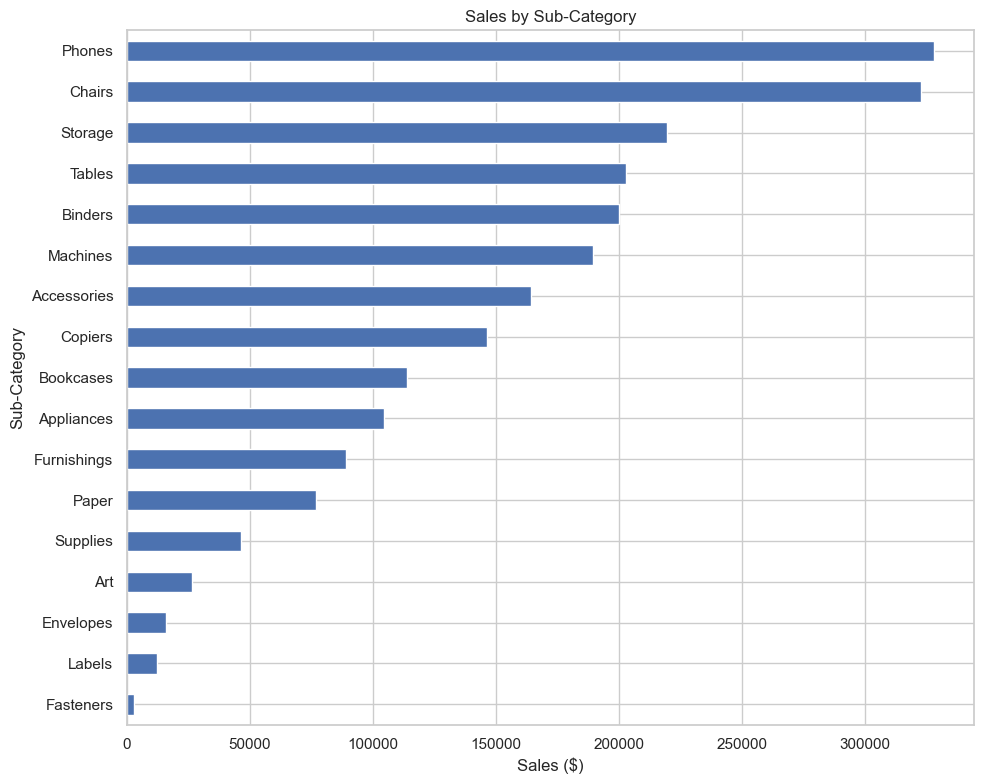

In [8]:
#Which sub-categories perform best?
subcategory_sales = (
    df.groupby("Sub-Category")["Sales"]
      .sum()
      .sort_values(ascending=True)
)

subcategory_sales.plot(kind="barh", figsize=(10, 8))

plt.title("Sales by Sub-Category")
plt.xlabel("Sales ($)")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.show()

,Total Sales
Region,
West,710219.6845
East,669518.7260
Central,492646.9132
South,389151.4590


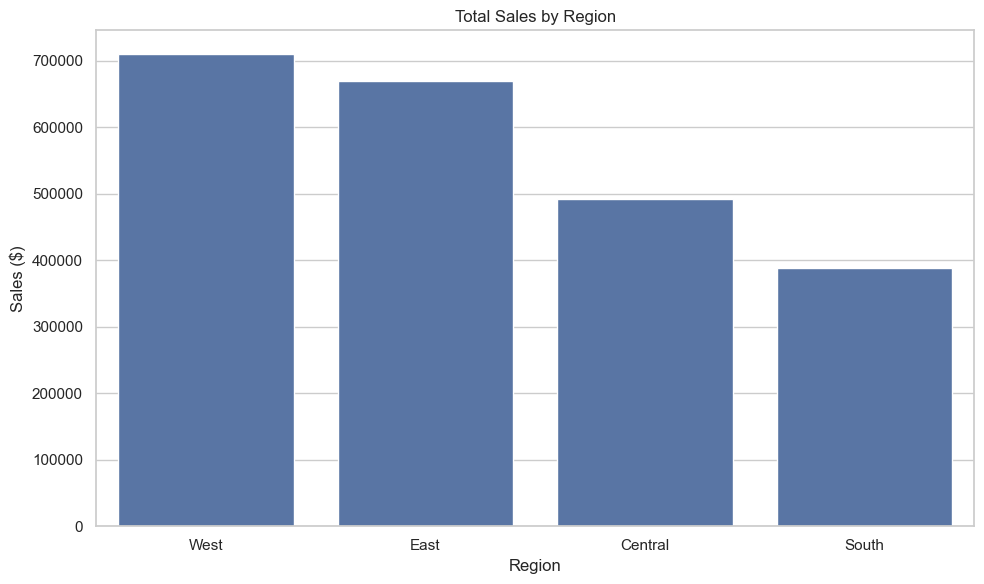

In [9]:
#Which regions generate the most sales?

region_sales = (
    df.groupby("Region")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

display(region_sales.to_frame("Total Sales"))

sns.barplot(
    data=region_sales.reset_index(),
    x="Region",
    y="Sales"
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales ($)")
plt.tight_layout()
plt.show()

,Total_Sales,Unique_Customers,Unique_Orders
Segment,,,
Consumer,1.148061e+06,409,2537
Corporate,6.884941e+05,236,1491
Home Office,4.249822e+05,148,894


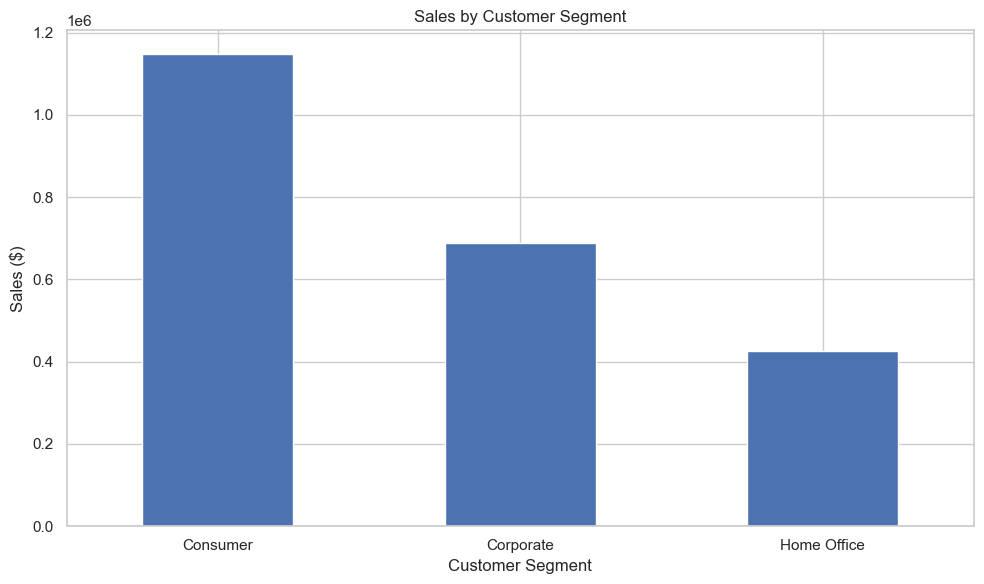

In [10]:
#Which customer segments contribute the most?

segment_sales = (
    df.groupby("Segment")
      .agg(
          Total_Sales=("Sales", "sum"),
          Unique_Customers=("Customer ID", "nunique"),
          Unique_Orders=("Order ID", "nunique")
      )
      .sort_values("Total_Sales", ascending=False)
)

display(segment_sales)

segment_sales["Total_Sales"].plot(kind="bar", rot=0)

plt.title("Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Sales ($)")
plt.tight_layout()
plt.show()

In [19]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    errors="coerce",
    dayfirst=True
)

print(df["Order Date"].dtype)

datetime64[us]


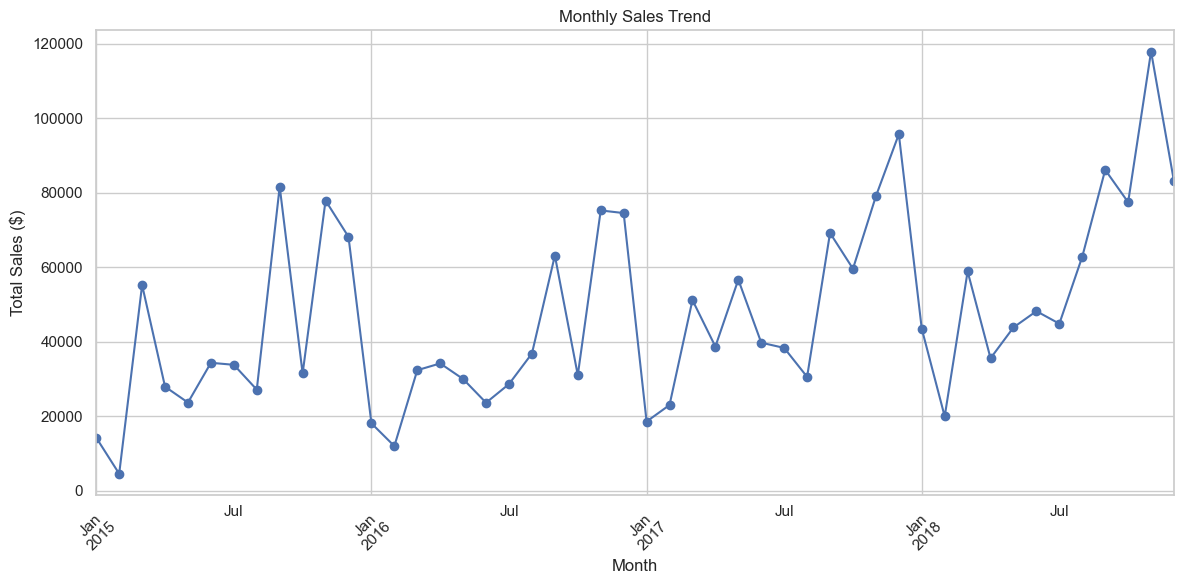

In [20]:
#How do sales change over time?

df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")

monthly_sales = (
    df.dropna(subset=["Order Date"])
      .set_index("Order Date")["Sales"]
      .resample("MS")
      .sum()
)

monthly_sales.plot(
    marker="o",
    figsize=(12, 6)
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

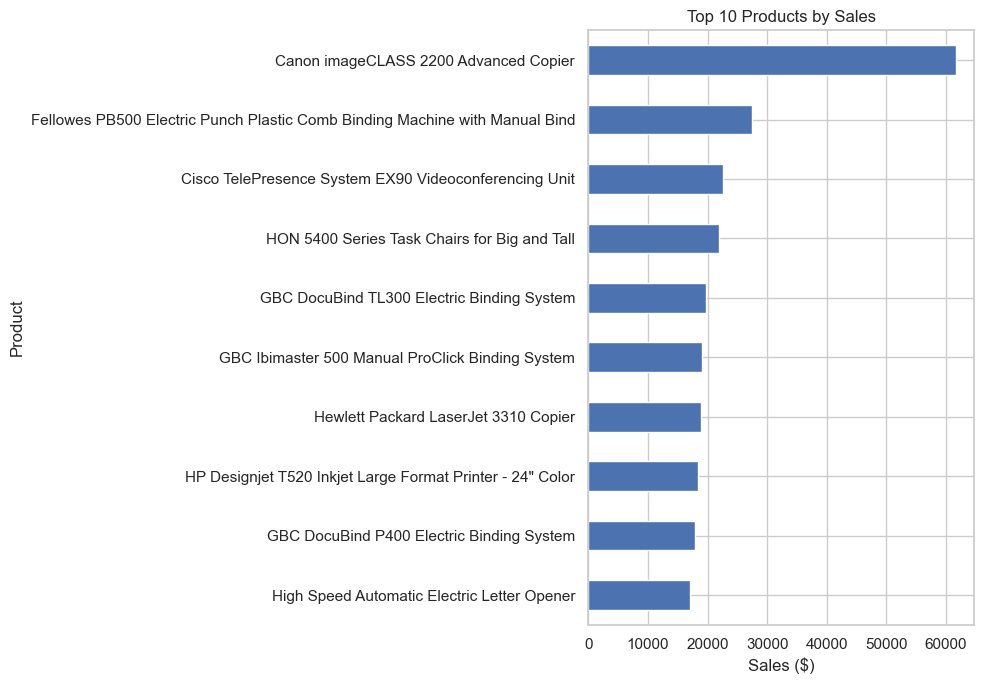

In [12]:
#Which products generate the highest sales?

top_products = (
    df.groupby("Product Name")["Sales"]
      .sum()
      .nlargest(10)
      .sort_values()
)

top_products.plot(kind="barh", figsize=(10, 7))

plt.title("Top 10 Products by Sales")
plt.xlabel("Sales ($)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

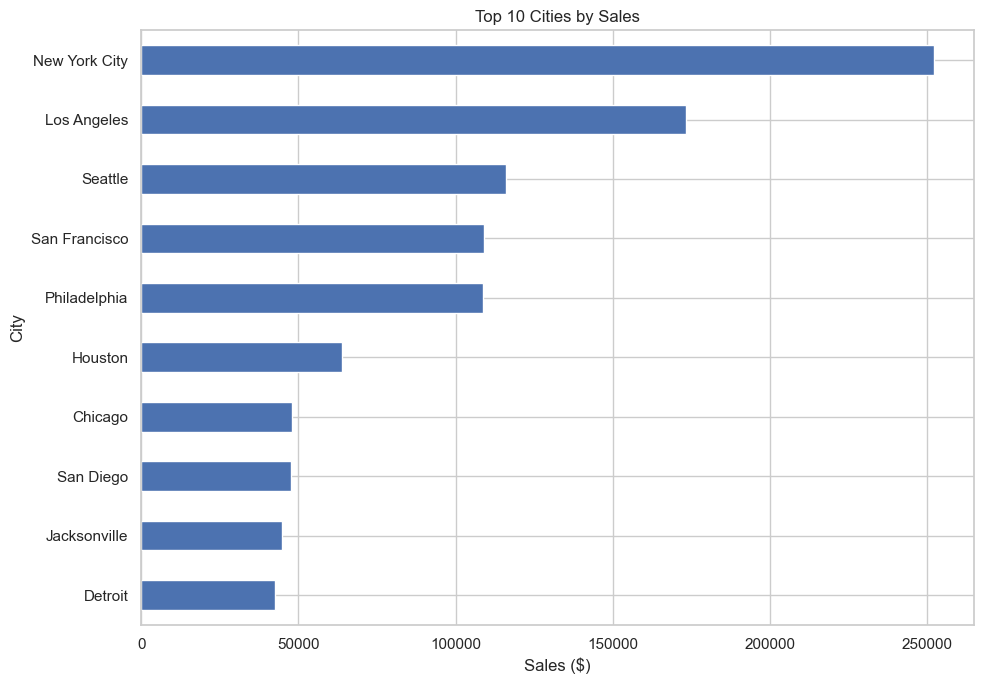

In [13]:
#Which cities contribute the most sales?

top_cities = (
    df.groupby("City")["Sales"]
      .sum()
      .nlargest(10)
      .sort_values()
)

top_cities.plot(kind="barh", figsize=(10, 7))

plt.title("Top 10 Cities by Sales")
plt.xlabel("Sales ($)")
plt.ylabel("City")
plt.tight_layout()
plt.show()

,Number of Records
Ship Mode,
Standard Class,5859
Second Class,1902
First Class,1501
Same Day,538


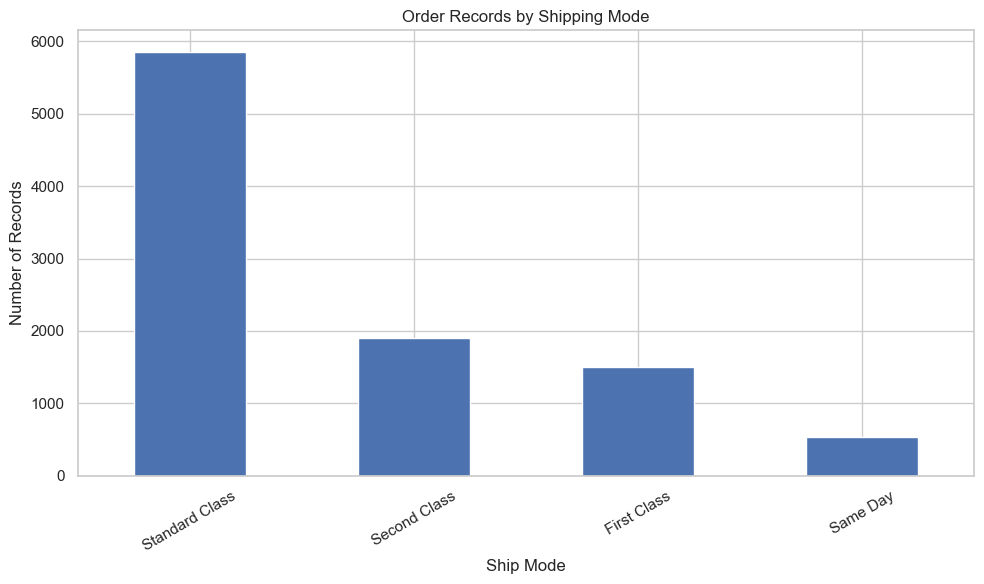

In [14]:
#Which shipping modes are most commonly used?

ship_mode_counts = df["Ship Mode"].value_counts()

display(ship_mode_counts.to_frame("Number of Records"))

ship_mode_counts.plot(kind="bar", rot=30)

plt.title("Order Records by Shipping Mode")
plt.xlabel("Ship Mode")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

In [21]:
# Convert both date columns to datetime format
df["Order Date"] = pd.to_datetime(
    df["Order Date"].astype(str),
    dayfirst=True,
    errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"].astype(str),
    dayfirst=True,
    errors="coerce"
)

# Verify the data types
print(df[["Order Date", "Ship Date"]].dtypes)

Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object


Shipping days summary:


count    3959.000000
mean       50.005304
std       140.633493
min      -319.000000
25%       -54.000000
50%        36.000000
75%       152.000000
max       331.000000
Name: Shipping Days, dtype: float64

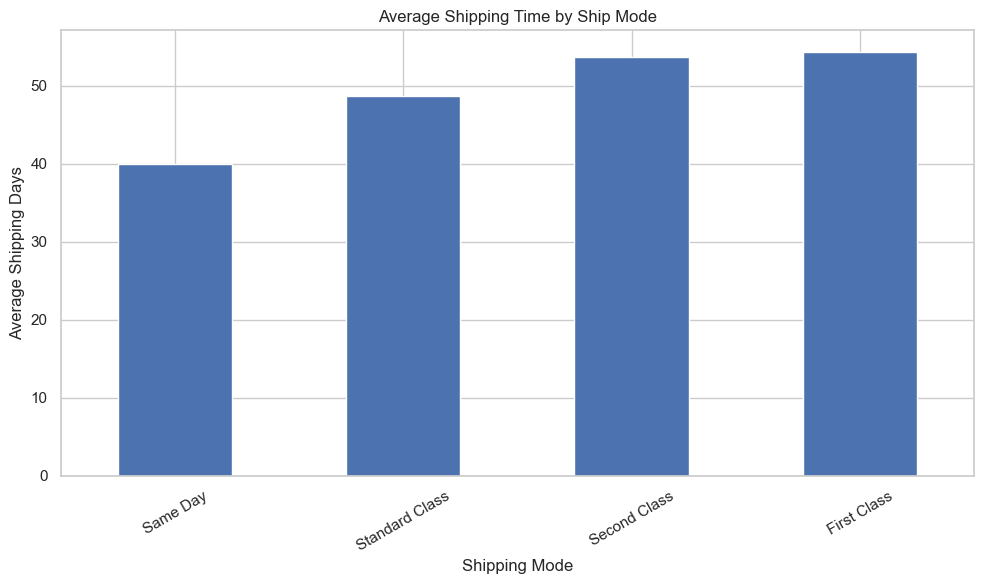

In [22]:
#How long does shipping take?

# Calculate shipping duration in days
df["Shipping Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

print("Shipping days summary:")
display(df["Shipping Days"].describe())

shipping_by_mode = (
    df.groupby("Ship Mode")["Shipping Days"]
      .mean()
      .sort_values()
)

shipping_by_mode.plot(
    kind="bar",
    figsize=(10, 6),
    rot=30
)

plt.title("Average Shipping Time by Ship Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Average Shipping Days")
plt.tight_layout()
plt.show()


Lower bound: -272.7875000000001
Upper bound: 500.6405000000001
Potential sales outliers: 1145


,Order ID,Product Name,Category,Sales
1,CA-2017-152156,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",Furniture,731.9400
3,US-2016-108966,Bretford CR4500 Series Slim Rectangular Table,Furniture,957.5775
7,CA-2015-115812,Mitel 5320 IP Phone VoIP phone,Technology,907.1520
10,CA-2015-115812,Chromcraft Rectangular Conference Tables,Furniture,1706.1840
11,CA-2015-115812,Konftel 250 Conference phone - Charcoal black,Technology,911.4240
16,CA-2015-105893,"Stur-D-Stor Shelving, Vertical 5-Shelf: 72""H x...",Office Supplies,665.8800
24,CA-2016-106320,Bretford CR4500 Series Slim Rectangular Table,Furniture,1044.6300
27,US-2016-150630,"Riverside Palais Royal Lawyers Bookcase, Royal...",Furniture,3083.4300
35,CA-2017-117590,GE 30524EE4,Technology,1097.5440
38,CA-2016-117415,"Atlantic Metals Mobile 3-Shelf Bookcases, Cust...",Furniture,532.3992


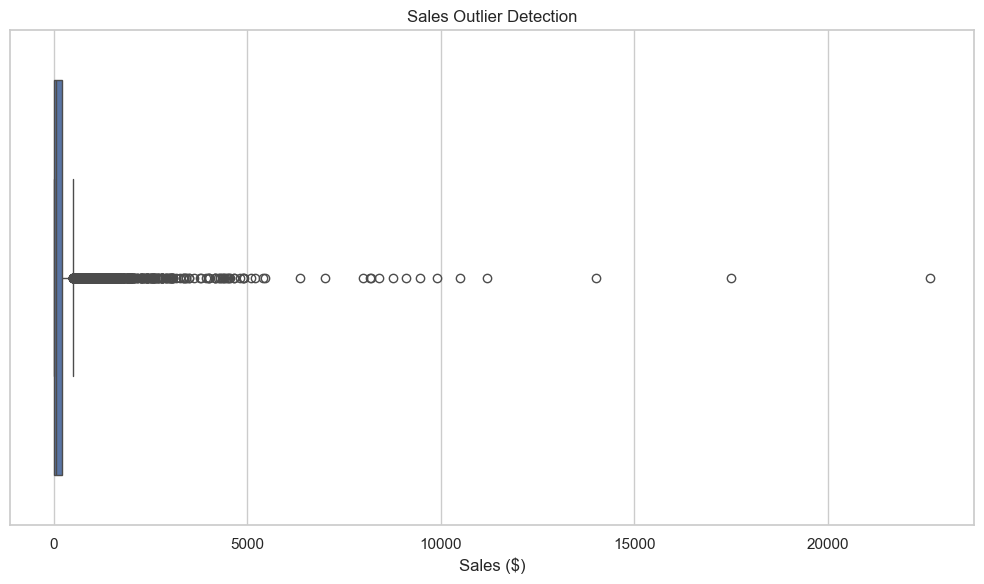

In [16]:
#Identify sales outliers

q1 = df["Sales"].quantile(0.25)
q3 = df["Sales"].quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

sales_outliers = df[
    (df["Sales"] < lower_bound) |
    (df["Sales"] > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Potential sales outliers:", len(sales_outliers))

display(
    sales_outliers[
        ["Order ID", "Product Name", "Category", "Sales"]
    ].head(20)
)

sns.boxplot(x=df["Sales"])

plt.title("Sales Outlier Detection")
plt.xlabel("Sales ($)")
plt.tight_layout()
plt.show()

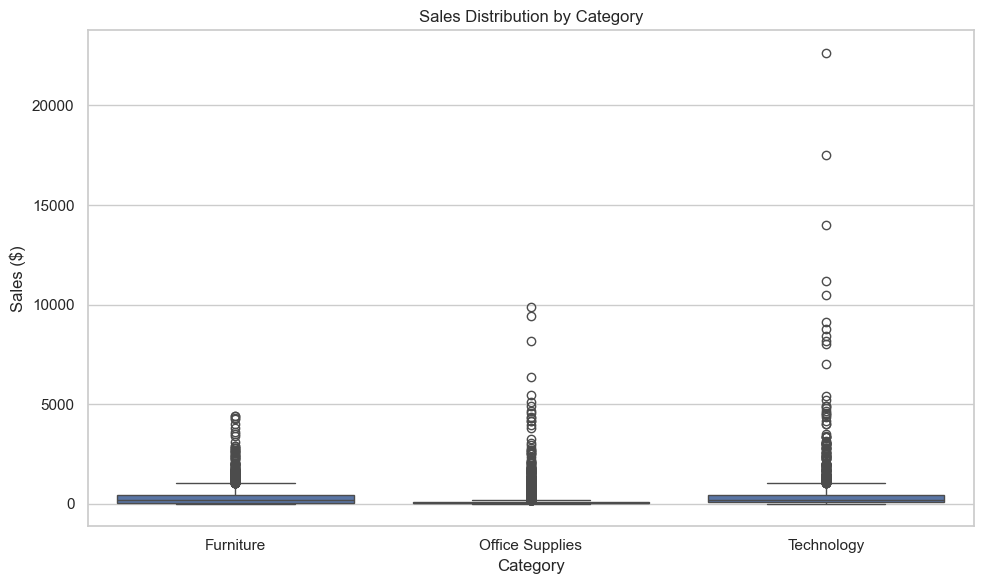

In [17]:
# Sales distribution by product category
sns.boxplot(
    data=df,
    x="Category",
    y="Sales"
)

plt.title("Sales Distribution by Category")
plt.xlabel("Category")
plt.ylabel("Sales ($)")
plt.tight_layout()
plt.show()

In [18]:
#Automatically generate key findings

best_category = df.groupby("Category")["Sales"].sum().idxmax()
best_region = df.groupby("Region")["Sales"].sum().idxmax()
best_segment = df.groupby("Segment")["Sales"].sum().idxmax()
best_subcategory = df.groupby("Sub-Category")["Sales"].sum().idxmax()

print("========== KEY FINDINGS ==========")

print(f"1. Highest-sales category: {best_category}")
print(f"2. Highest-sales region: {best_region}")
print(f"3. Highest-sales customer segment: {best_segment}")
print(f"4. Highest-sales sub-category: {best_subcategory}")

print(f"5. Total sales: ${total_sales:,.2f}")
print(f"6. Unique orders: {total_orders:,}")
print(f"7. Unique customers: {total_customers:,}")
print(f"8. Potential sales outliers: {len(sales_outliers)}")

========== KEY FINDINGS ==========
1. Highest-sales category: Technology
2. Highest-sales region: West
3. Highest-sales customer segment: Consumer
4. Highest-sales sub-category: Phones
5. Total sales: $2,261,536.78
6. Unique orders: 4,922
7. Unique customers: 793
8. Potential sales outliers: 1145
